# Bout segmentation — GsizeMotionSingle (visual-stimulus) dataset

This notebook walks step by step through **segmenting continuous tracking into discrete swim bouts**, adapting the bout-detection method of **Le Goc et al. 2021** (*Thermal modulation of Zebrafish exploratory statistics*, BMC Biology, doi:10.1186/s12915-021-01126-w) to this experiment.

**Input** — the per-fish `*_transformed_abs.csv` files (the `abs_dict` / `df_abs_raw` representation): continuous tracking at **30 fps**, columns `frame, stimulus, f{N}_x, f{N}_y, f{N}_ori, d0_x..d7_stim`. Positions are in **camera pixels**; orientation in **radians (CCW, 0 = right)**.

**Output** — a tidy **per-bout** dataframe (one row per detected bout) with the core kinematics (reorientation angle `dtheta`, interbout interval `dt`, traveled distance) **plus the visual-stimulus context** of each bout.

**Design decisions** (the same as the script `scripts/segment_bouts.py`):
- **Two anchors per bout**: the **onset** is the speed *trough* (bout start) — used for timing, position, stimulus context, and as the **heading/distance anchor**; the **peak** (active phase) is kept for the body-orientation cross-check.
- Heading / `dtheta`: **displacement-derived from the discretized bout positions** — `theta_i = dir(onset_{i+1} − onset_i)`, the net travel from each bout to the next (i.e. the direction the fish actually goes *until* the next bout), robust to where in the bout the speed peaks and to 180° body-orientation flips.
- **Smoothing is a detection aid only.** Gaussian position smoothing is used *only* to find the onset/peak frames (integer-pixel jitter otherwise spawns spurious speed peaks); heading, distance and position are all measured from the **raw** positions, so smoothing never distorts the direction we report.
- Trajectory split: **only at tracking gaps**. A bout's reorientation may span a pause→stimulus transition, which preserves the **onset reorientation** (the fish turning toward newly-appeared dots) — the signal of this semi-closed-loop assay (dots simulate conspecifics). Each bout is **tagged by the stimulus condition active at its onset**.

**Le Goc parameters, reconverted 25 fps → 30 fps:** refractory = 0.4 s (12 frames); displacement window = ±0.5 s (±15 frames); displacement gate 0.3–18 mm. (Onset is the speed trough by default; the Le Goc literal "80 ms before the peak" is available as `onset_mode="lead"`.)

## 1. Imports, constants, and locating the data

In [42]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---- constants (match scripts/segment_bouts.py) ----
FPS = 30.0
# PIXEL-NATIVE: distances/positions are reported in PIXELS. We do NOT scale per
# fish (the ROIdef radius is trajectory-derived, not a physical dish measurement,
# so 50/radius has no independent basis). A single global nominal PX_PER_MM is
# used only to (a) convert Le Goc's physical thresholds to px and (b) emit a
# nominal-mm column. Angles/dtheta/HMM are scale-free regardless.
PX_PER_MM = 3.67               # repo nominal projector scale (transformed_data_pipeline.py)
POS_SMOOTH_SIGMA = 2.0         # Gaussian trajectory smoothing (frames) for heading
BOUT_LEAD_FR = round(0.08 * FPS)   # 80 ms before peak -> onset (=2 frames)
REFRACTORY_FR = round(0.40 * FPS)  # min frames between bouts (=12)
DISP_WIN_FR = round(0.50 * FPS)    # +/- displacement window (=15)
DISP_MIN_MM, DISP_MAX_MM = 0.3, 18.0        # Le Goc physical gate (documentation)
DISP_MIN_PX = DISP_MIN_MM * PX_PER_MM       # = 1.101 px (gate applied in pixels)
DISP_MAX_PX = DISP_MAX_MM * PX_PER_MM       # = 66.06 px
WALL_SHELL_PX = 5.0 * PX_PER_MM             # = 18.35 px (Le Goc 5 mm near-wall shell)
SMOOTH_FR = 3                  # speed smoothing (frames)
FORWARD_THRESH_DEG = 10.0      # |dtheta| < 10 deg -> forward (Le Goc / HMM)
STIM_NONE = {"none", "inter_stim_pause", "bout", "None", None}

# ---- locate repo data whether we run from notebooks/ or repo root ----
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
INPUT_DIR = ROOT / "data" / "data" / "df_transformed"
ROI_PATH = ROOT / "data" / "data" / "ROIdef.csv"
OUT_CSV = ROOT / "data" / "bouts_GsizeMotionSingle.csv"
csvs = sorted(INPUT_DIR.glob("*_transformed_abs.csv"))
print(f"ROOT       : {ROOT}")
print(f"per-fish csvs found: {len(csvs)}")
print(csvs[0].name if csvs else "(none)")

ROOT       : c:\Users\arthu\mp_semiCL_behavior
per-fish csvs found: 15
2025.02.20_GsizeMotionSingle_f0_transformed_abs.csv


## 2. Look at the raw input — this is the *before-segmentation* form

Each row is one **frame** (30 fps). The fish never moves much per frame; a *bout* is a short burst of speed every ~1 s. We load one fish to inspect the structure and value ranges.

In [43]:
df0 = pd.read_csv(csvs[0])
prefix0 = next(re.match(r"(f\d+)_x$", c).group(1) for c in df0.columns if re.match(r"(f\d+)_x$", c))
print("shape:", df0.shape, "| fish prefix:", prefix0)
print("duration:", round(len(df0) / FPS / 60, 1), "min")
display(df0[["frame", "stimulus", f"{prefix0}_x", f"{prefix0}_y", f"{prefix0}_ori"]].head())
for c in [f"{prefix0}_x", f"{prefix0}_y", f"{prefix0}_ori"]:
    s = df0[c]
    print(f"{c}: min={np.nanmin(s):.2f} max={np.nanmax(s):.2f} nan_frac={s.isna().mean():.4f} integer={np.allclose(s.dropna(), s.dropna().round())}")
print("\nstimulus blocks (top):", df0["stimulus"].value_counts().head(6).to_dict())

shape: (313500, 29) | fish prefix: f0
duration: 174.2 min


,frame,stimulus,f0_x,f0_y,f0_ori
0,0,inter_stim_pause,NaN,NaN,NaN
1,1,inter_stim_pause,NaN,NaN,NaN
2,2,inter_stim_pause,NaN,NaN,NaN
3,3,inter_stim_pause,NaN,NaN,NaN
4,4,inter_stim_pause,NaN,NaN,NaN


f0_x: min=105.00 max=323.00 nan_frac=0.0005 integer=True
f0_y: min=122.00 max=339.00 nan_frac=0.0005 integer=True
f0_ori: min=0.00 max=6.28 nan_frac=0.0005 integer=False

stimulus blocks (top): {'inter_stim_pause': 142500, 'CLsemi1800_g4-0_s3.5-3.5': 10800, 'CLsemi1800_g0-2_s3.5-3.5': 10800, 'CLsemi1800_g0-4_s3.5-3.5': 10800, 'CLsemi1800_g8-0_s3.5-3.5': 10800, 'CLsemi1800_g0-4_s0-0': 10800}


**Two things to note** (they drive the pipeline):
1. `f{N}_x/_y` are **integer pixels** — sub-pixel precision was lost upstream. This quantizes short bouts and adds noise to heading (we mitigate with trajectory smoothing).
2. The `stimulus` column alternates between `inter_stim_pause` (50 s) and `CLsemi...` stimulus blocks (60 s). We do **not** cut trajectories at these boundaries (only at tracking gaps), so the bout where the fish first reacts to a newly-appeared stimulus keeps its reorientation; each bout is labelled by the condition active at its onset.

## 3. Units: we work in **pixels** (no per-fish scaling)

Earlier versions converted fish positions to millimetres with a **per-fish** scale $s_f = 50\,\text{mm}/\texttt{radius}_f$. We discovered that `ROIdef.radius_f` is **exactly the 99.5th percentile of each fish's own trajectory** (ratio 1.000 for all 15 fish) and `ROIdef.(x,y)` equals each fish's median — so that "scale" is *trajectory-derived, not a physical dish measurement*, and its validation was circular. There is no independent per-dish geometry in the shipped data.

So this notebook is **pixel-native**:

- **Distances/positions are reported in pixels** (`distance_px`, `x_px`, `y_px`). This is the tracking unit and needs no assumption.
- A **single global nominal** `PX_PER_MM = 3.67` (the repo's projector scale, applied only to the stimulus dots upstream) is used **only** to (a) convert Le Goc's physical bout thresholds (0.3–18 mm gate, 5 mm wall shell) to pixels and (b) emit a `distance_nominal_mm = distance_px / 3.67` column for rough interpretability — flagged as *nominal*, not per-dish.
- **Angles are scale-free.** `dtheta`, heading, `bout_type`, the HMM fit, and the evaluation likelihood (Metric A) are `atan2`-based and identical in any unit — the whole turning story is unaffected by this choice.
- The **only** scale-dependent step is the displacement gate; using one global pixel gate (vs the old per-fish one) changes ~0.8% of bouts near the gate edges — a deliberate, small consequence of dropping the unjustified per-fish scale.

The `ROIdef` file is still loaded below **only** to draw each dish's circle in the exploration plots (Section 3b) — not to scale anything.

In [44]:
# ROIdef is loaded ONLY to draw each dish's circle in the exploration plots below.
# It is NOT used to scale anything (the pipeline is pixel-native).
roi = pd.read_csv(ROI_PATH, header=None,
                  names=["xoff", "yoff", "diameter", "x", "y", "radius"])
print("ROIdef loaded (used only for the dish circle in Section 3b, not for scaling).")
print(f"nominal scale for the interpretability column: PX_PER_MM = {PX_PER_MM} "
      f"(distance_nominal_mm = distance_px / {PX_PER_MM})")

ROIdef loaded (used only for the dish circle in Section 3b, not for scaling).
nominal scale for the interpretability column: PX_PER_MM = 3.67 (distance_nominal_mm = distance_px / 3.67)


### 3b. Where did each fish actually go? (exploration — not a scale calibration)

We do **not** use `ROIdef` to scale anything (the pipeline is pixel-native). These two panels are pure exploration of the tracking, with the ROIdef circle drawn only for reference:

1. **Occupancy heatmap**, **dish-centred** — each panel spans the full ROI radius on a light background, with **log** colour so sparse edge visits stay visible rather than the dense centre eating the whole colour range. This shows where each fish went across the *whole* dish. Most fish cover the bulk of their dish; **f6/f14** occupy only a lopsided sub-region (tracking-quality outliers).

2. **Radial occupancy** (below) — a check that the fish are **not swimming in a ring**: the distribution rises from the centre and tails off *before* the wall, instead of spiking at $r=1$ (which is what a wall-following / circling fish would produce).

> **Why `ROIdef` is not a scale.** Its `(x,y)` equals each fish's median position and its `radius` equals the 99.5th percentile of the fish's own radial excursion (verified, ratio 1.000 for all 15) — so it is a *summary of the trajectory*, not an independent dish measurement. That is exactly why the old "p99/ROI ≈ 0.96, so the per-dish scale is validated" reasoning was circular, and why we dropped per-fish scaling. The circle below is a visual reference only.
>
> *(Earlier the path was drawn as faint `,`-markers with two overlaid circles; the dense centre washed out and the eye latched onto the circles, giving a false "the fish circles the dish" impression — a rendering artefact, since the trajectories actually fill the dish.)*

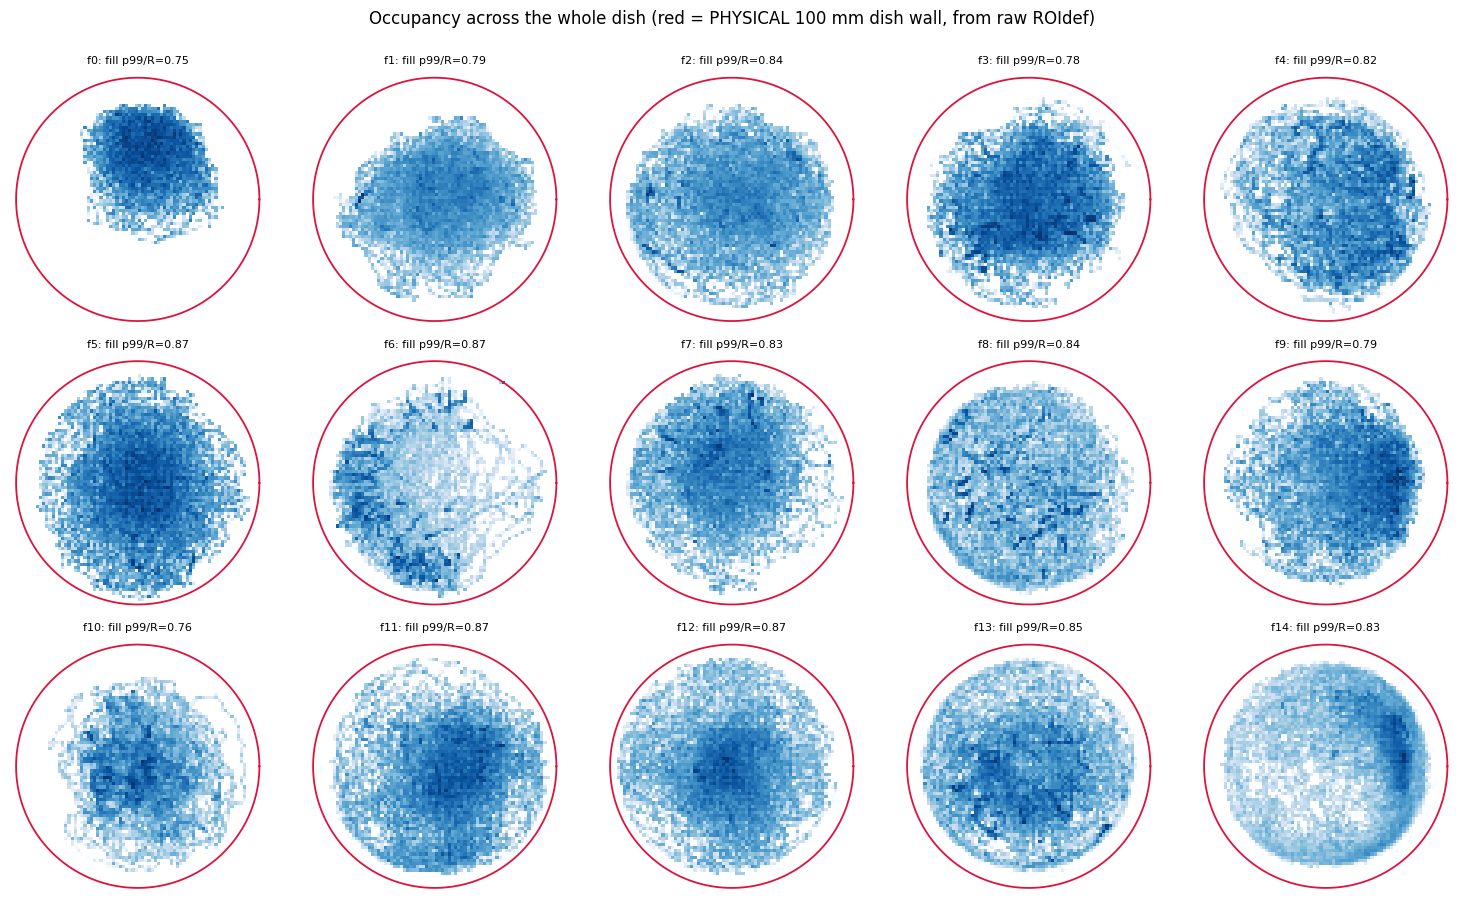

physical dish radius : mean 177.9 px  (~50 mm at 3.60 px/mm)
explored p99 / wall  : mean 0.82  (fish fill ~82% of the real dish)
frames beyond wall   : mean 0.00%  (~0 => red circle is the true boundary)


In [45]:
from matplotlib.colors import LogNorm

# PHYSICAL dish wall from the RAW ROI file (the real 100 mm dish), mapped into this
# y-flipped transformed frame: centre=(x-xoff, diameter-(y-yoff)), radius unchanged.
# Unlike data/data/ROIdef.csv (whose radius is each fish's own p99.5 excursion), this
# is the true boundary -- verified: 0% of tracked frames fall outside it.
roi_phys = pd.read_csv(ROOT / 'data' / 'data' / 'Original_data' / 'ROIdef2025-02-20T12_09_16.csv',
                       header=None, names=['xoff', 'yoff', 'diameter', 'x', 'y', 'radius'])
roi_phys['cx'] = roi_phys['x'] - roi_phys['xoff']
roi_phys['cy'] = roi_phys['diameter'] - (roi_phys['y'] - roi_phys['yoff'])
PX_PER_MM_PHYS = roi_phys['diameter'].mean() / 100.0          # 100 mm dish -> ~3.60 px/mm

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
fill, frac_out = [], []
th = np.linspace(0, 2 * np.pi, 200)
for fid in range(15):
    fdf = pd.read_csv(INPUT_DIR / f'2025.02.20_GsizeMotionSingle_f{fid}_transformed_abs.csv',
                      usecols=[f'f{fid}_x', f'f{fid}_y'])
    x = fdf[f'f{fid}_x'].dropna().to_numpy(); y = fdf[f'f{fid}_y'].dropna().to_numpy()
    cx, cy, r_phys = roi_phys.loc[fid, 'cx'], roi_phys.loc[fid, 'cy'], roi_phys.loc[fid, 'radius']
    r = np.hypot(x - cx, y - cy)
    fill.append(np.quantile(r, 0.99) / r_phys)               # how much of the dish is used
    frac_out.append(np.mean(r > r_phys))                     # should be ~0 (fish stay inside)
    ax = axes.flat[fid]
    lim = 1.05 * r_phys                                       # dish-centred on the PHYSICAL centre
    ax.hist2d(x, y, bins=80, range=[[cx - lim, cx + lim], [cy - lim, cy + lim]],
              cmap='Blues', cmin=1, norm=LogNorm())
    ax.plot(cx + r_phys * np.cos(th), cy + r_phys * np.sin(th), '-', color='crimson', lw=1.3)  # physical wall
    ax.set_xlim(cx - lim, cx + lim); ax.set_ylim(cy - lim, cy + lim)
    ax.set_title(f'f{fid}: fill p99/R={fill[-1]:.2f}', fontsize=8)
    ax.set_aspect('equal'); ax.axis('off')
plt.suptitle('Occupancy across the whole dish (red = PHYSICAL 100 mm dish wall, from raw ROIdef)', y=1.0)
plt.tight_layout(); plt.show()
r_mean = roi_phys['radius'].mean()
print(f'physical dish radius : mean {r_mean:.1f} px  (~50 mm at {PX_PER_MM_PHYS:.2f} px/mm)')
print(f'explored p99 / wall  : mean {np.mean(fill):.2f}  (fish fill ~{100*np.mean(fill):.0f}% of the real dish)')
print(f'frames beyond wall   : mean {100*np.mean(frac_out):.2f}%  (~0 => red circle is the true boundary)')

#### Is that red circle the physical dish wall? No — and note it *is* in pixels

A quick aside on the wording, since it trips people up. **`ROIdef` is in the same camera pixels** as `f{N}_x/_y`. "Pixel-native" does **not** mean ROIdef has some other unit — it means the whole pipeline stays in those pixels and never uses ROIdef to *rescale* them into millimetres (the dropped `s_f = 50 mm / radius_f` step). So "ROIdef is in pixels" and "we don't use ROIdef to scale anything" are **both** true at once: the first is about the *unit* ROIdef is stored in, the second about a *unit conversion* we no longer do.

What ROIdef is **not** is the **physical rim of the dish**. `radius_f` was set to the **99.5th percentile of each fish's own radial excursion** (centre = the fish's median), so it is a summary *of the trajectory*, not a measured wall. The next cell makes that concrete: if the red circle were a real wall, essentially **zero** frames could sit outside it — a fish cannot swim through glass. Instead **~0.5 % of every fish's frames fall past it** (exactly what a p99.5 cutoff produces by construction), and the furthest excursions reach **~10–20 % beyond** it.

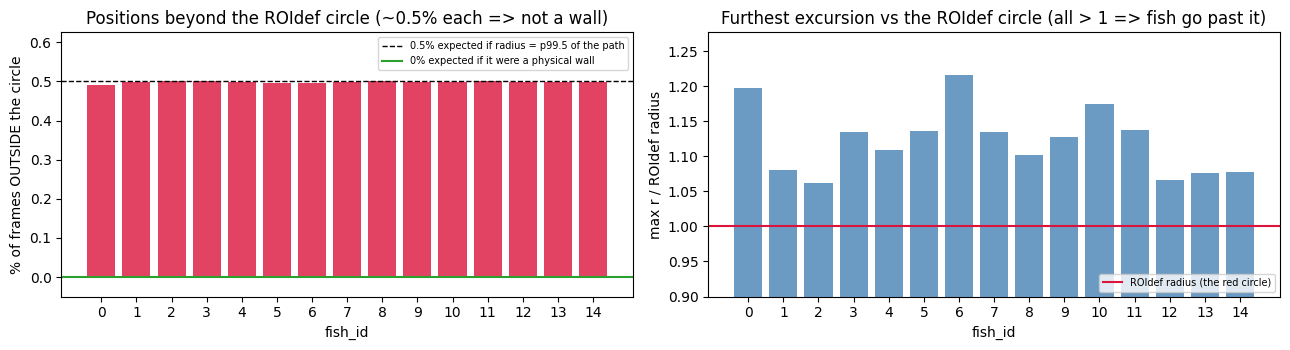

frames beyond the ROIdef circle : mean 0.50% per fish (23,407 frames outside the border in total)
a physical dish wall would give : ~0% (a fish cannot swim through the glass)
furthest excursion / radius     : mean 1.12x, up to 1.22x => fish reach ~12% PAST the border
=> the red circle is the 99.5th percentile of the path itself, NOT the dish rim.


In [46]:
# Proof that the ROIdef circle is NOT the physical dish boundary: count the tracked
# positions that fall OUTSIDE it. A real wall cannot be crossed -> ~0% beyond, and r
# would pile up AT the rim as a hard max. Instead every fish leaks ~0.5% of its frames
# past the circle -- because ROIdef.radius IS the p99.5 of that fish's own r -- and
# reaches ~5-20% beyond it. Everything here is in the SAME camera pixels as the
# tracking; nothing is scaled (that is all 'pixel-native' means).
pct_beyond, max_ratio, n_beyond = [], [], []
for fid in range(15):
    fdf = pd.read_csv(INPUT_DIR / f'2025.02.20_GsizeMotionSingle_f{fid}_transformed_abs.csv',
                      usecols=[f'f{fid}_x', f'f{fid}_y'])
    x = fdf[f'f{fid}_x'].dropna().to_numpy(); y = fdf[f'f{fid}_y'].dropna().to_numpy()
    cx, cy, rr = roi.loc[fid, 'x'], roi.loc[fid, 'y'], roi.loc[fid, 'radius']   # all px
    r = np.hypot(x - cx, y - cy)                    # px, distance from the ROIdef centre
    pct_beyond.append(100 * np.mean(r > rr))        # % of frames OUTSIDE the red circle
    max_ratio.append(r.max() / rr)                  # how far past the border the fish reach
    n_beyond.append(int(np.sum(r > rr)))

fids = [str(i) for i in range(15)]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(fids, pct_beyond, color='crimson', alpha=0.8)
ax[0].axhline(0.5, color='k', ls='--', lw=1, label='0.5% expected if radius = p99.5 of the path')
ax[0].axhline(0.0, color='tab:green', lw=1.5, label='0% expected if it were a physical wall')
ax[0].set_ylim(-0.05, max(pct_beyond) * 1.25)
ax[0].set_ylabel('% of frames OUTSIDE the circle'); ax[0].set_xlabel('fish_id')
ax[0].set_title('Positions beyond the ROIdef circle (~0.5% each => not a wall)')
ax[0].legend(fontsize=7, loc='upper right')
ax[1].bar(fids, max_ratio, color='steelblue', alpha=0.8)
ax[1].axhline(1.0, color='crimson', lw=1.5, label='ROIdef radius (the red circle)')
ax[1].set_ylim(0.9, max(max_ratio) * 1.05)
ax[1].set_ylabel('max r / ROIdef radius'); ax[1].set_xlabel('fish_id')
ax[1].set_title('Furthest excursion vs the ROIdef circle (all > 1 => fish go past it)')
ax[1].legend(fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()

print(f'frames beyond the ROIdef circle : mean {np.mean(pct_beyond):.2f}% per fish '
      f'({sum(n_beyond):,} frames outside the border in total)')
print('a physical dish wall would give : ~0% (a fish cannot swim through the glass)')
print(f'furthest excursion / radius     : mean {np.mean(max_ratio):.2f}x, up to {np.max(max_ratio):.2f}x '
      f'=> fish reach ~{100*(np.mean(max_ratio)-1):.0f}% PAST the border')
print('=> the red circle is the 99.5th percentile of the path itself, NOT the dish rim.')

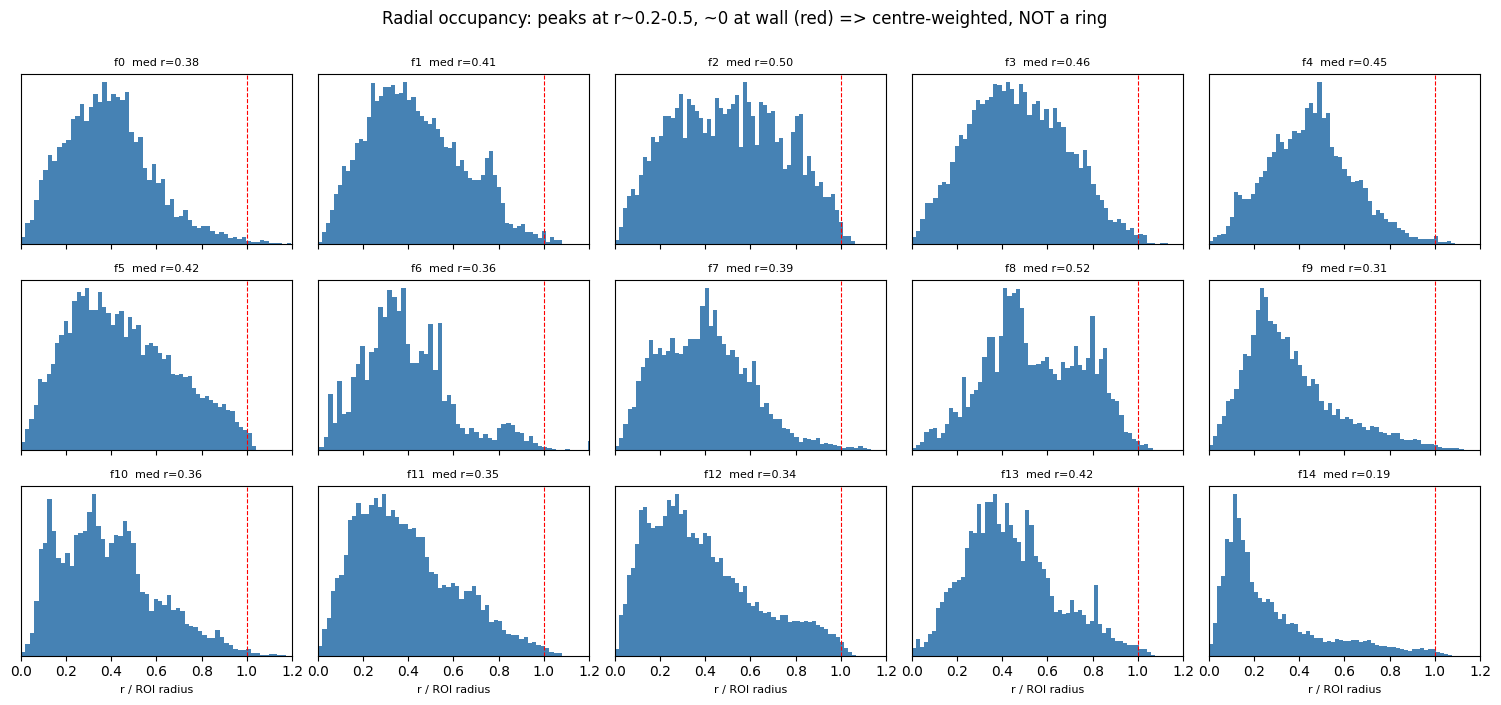

time in outer shell (r>0.8): mean 0.07  (area-uniform would give 0.36)
time in inner core  (r<0.5): mean 0.67  (area-uniform would give 0.25)
=> fish sit in the CENTRE; the earlier 'perfect circles' were a scatter-render artefact.


In [47]:
# Decisive check that the fish are NOT "swimming in circles": radial occupancy.
# A ring / wall-follower peaks near r=1; uniform-area exploration rises ~linearly
# to the edge. Instead every fish PEAKS at r~0.2-0.5 and falls to ~0 at the wall
# -> centre-weighted exploration. (This is exactly why the old ,-scatter misled:
# the density is in the MIDDLE, not on a circle.)
fig, axes = plt.subplots(3, 5, figsize=(15, 7), sharex=True)
outer, inner = [], []
for fid in range(15):
    fdf = pd.read_csv(INPUT_DIR / f"2025.02.20_GsizeMotionSingle_f{fid}_transformed_abs.csv",
                      usecols=[f"f{fid}_x", f"f{fid}_y"])
    x = fdf[f"f{fid}_x"].dropna().to_numpy(); y = fdf[f"f{fid}_y"].dropna().to_numpy()
    cx, cy, rr = roi.loc[fid, "x"], roi.loc[fid, "y"], roi.loc[fid, "radius"]
    r = np.hypot(x - cx, y - cy) / rr
    outer.append(np.mean(r > 0.8)); inner.append(np.mean(r < 0.5))
    ax = axes.flat[fid]
    ax.hist(r, bins=60, color="steelblue")
    ax.axvline(1.0, color="r", ls="--", lw=0.8)
    ax.set_title(f"f{fid}  med r={np.median(r):.2f}", fontsize=8)
    ax.set_xlim(0, 1.2); ax.set_yticks([])
for ax in axes[-1]:
    ax.set_xlabel("r / ROI radius", fontsize=8)
plt.suptitle("Radial occupancy: peaks at r~0.2-0.5, ~0 at wall (red) => centre-weighted, NOT a ring", y=1.0)
plt.tight_layout(); plt.show()
print(f"time in outer shell (r>0.8): mean {np.mean(outer):.2f}  (area-uniform would give 0.36)")
print(f"time in inner core  (r<0.5): mean {np.mean(inner):.2f}  (area-uniform would give 0.25)")
print("=> fish sit in the CENTRE; the earlier 'perfect circles' were a scatter-render artefact.")

## 4. Helper functions

These mirror `scripts/segment_bouts.py`. We define them inline so each step is visible.

In [48]:
def wrap_pi(a):
    """Wrap angle(s) to (-pi, pi]."""
    return (np.asarray(a) + np.pi) % (2 * np.pi) - np.pi


def parse_stimulus(name):
    """Parse 'CLsemi1800_g{L}-{R}_s{sL}-{sR}' into stimulus-context fields."""
    out = dict(n_dots_left=np.nan, n_dots_right=np.nan,
               speed_left=np.nan, speed_right=np.nan, side="none", moving=False)
    if not isinstance(name, str) or not name.startswith("CLsemi"):
        return out
    mg = re.search(r"_g(\d+)-(\d+)", name)
    ms = re.search(r"_s([\d.]+)-([\d.]+)", name)
    if mg:
        L, R = int(mg.group(1)), int(mg.group(2))
        out["n_dots_left"], out["n_dots_right"] = L, R
        out["side"] = ("left" if L > 0 and R == 0 else
                       "right" if R > 0 and L == 0 else
                       "both" if L > 0 and R > 0 else "none")
    if ms:
        out["speed_left"], out["speed_right"] = float(ms.group(1)), float(ms.group(2))
        out["moving"] = (out["speed_left"] > 0) or (out["speed_right"] > 0)
    return out


def stim_angle_at(row, fx, fy, f_ori, n_stimuli=8):
    """Angle (rad, relative to fish facing f_ori) of the active-dot centroid."""
    xs, ys = [], []
    for k in range(n_stimuli):
        sc, xc, yc = f"d{k}_stim", f"d{k}_x", f"d{k}_y"
        if sc not in row or row[sc] in STIM_NONE or pd.isna(row.get(xc)):
            continue
        xs.append(row[xc]); ys.append(row[yc])
    if not xs:
        return np.nan
    return float(wrap_pi(np.arctan2(np.mean(ys) - fy, np.mean(xs) - fx) - f_ori))


def fish_xy_px(seg, prefix):
    """Sub-pixel-smoothed position (px). Smoothing fights the integer-pixel
    quantisation that otherwise spawns spurious speed peaks -- it is used for
    BOUT DETECTION only; heading/distance/position are measured from the raw
    pixel positions (see segment_fish), so smoothing never biases the direction."""
    x = seg[f"{prefix}_x"].to_numpy(dtype=float)
    y = seg[f"{prefix}_y"].to_numpy(dtype=float)
    if POS_SMOOTH_SIGMA > 0 and len(x) > 3:
        x = gaussian_filter1d(x, POS_SMOOTH_SIGMA)
        y = gaussian_filter1d(y, POS_SMOOTH_SIGMA)
    return x, y


def speed_px_s(x, y):
    """Instantaneous speed (px/s), lightly smoothed."""
    v = np.concatenate([[0.0], np.hypot(np.diff(x), np.diff(y))]) * FPS
    if SMOOTH_FR > 1:
        v = pd.Series(v).rolling(SMOOTH_FR, center=True, min_periods=1).mean().to_numpy()
    return v


def _snap_to_trough(v, p):
    """Walk back from speed peak p to the preceding local minimum (rest point)."""
    i = p
    while i > 0 and v[i - 1] <= v[i]:
        i -= 1
    return i


def detect_bouts(x, y, speed_thresh_k, onset_mode="trough"):
    """Detect bouts -> two aligned arrays (onsets, peaks).

    onset = bout START frame (timing / position / stimulus context / heading):
            'trough' = local speed minimum before the peak (default);
            'lead'   = Le Goc literal, BOUT_LEAD_FR frames before the peak.
    peak  = speed-peak frame, kept for the body-orientation cross-check.
    Positions are PIXELS; the displacement gate uses the pixel thresholds
    (DISP_MIN_PX .. DISP_MAX_PX = Le Goc 0.3-18 mm via the nominal PX_PER_MM).
    """
    n = len(x)
    if n < 2 * DISP_WIN_FR + 2:
        return np.array([], dtype=int), np.array([], dtype=int)
    v = speed_px_s(x, y)
    thr = np.nanmean(v) + speed_thresh_k * np.nanstd(v)
    peaks, _ = find_peaks(v, height=thr, distance=REFRACTORY_FR)
    if onset_mode == "trough":
        onsets = np.array([_snap_to_trough(v, p) for p in peaks], dtype=int)
    else:
        onsets = np.clip(peaks - BOUT_LEAD_FR, 0, n - 1)
    keep = []
    for o, p in zip(onsets, peaks):
        a, b = max(o - DISP_WIN_FR, 0), min(o + DISP_WIN_FR, n - 1)
        if DISP_MIN_PX <= np.hypot(x[b] - x[a], y[b] - y[a]) <= DISP_MAX_PX:
            keep.append((o, p))
    if not keep:
        return np.array([], dtype=int), np.array([], dtype=int)
    keep.sort()
    on = np.array([k[0] for k in keep]); pk = np.array([k[1] for k in keep])
    _, idx = np.unique(on, return_index=True)   # drop rare duplicate onsets
    return on[idx], pk[idx]


print("helpers defined.")

helpers defined.


## 5. Step-through on ONE stimulus block — speed trace and detected bouts

We pick one `CLsemi...` block of fish 0, compute the speed, and mark each bout. Two anchors per bout:
- **green ● = onset (trough)** — the speed minimum *before* the burst, i.e. where the fish starts accelerating (the physical bout start). Used for timing, position, stimulus context, and as the heading/distance anchor (heading is read onset-to-onset; see Sect. 7).
- **red ▾ = speed peak** — the active phase of the bout. Kept for the body-orientation cross-check and the per-bout speed readout.

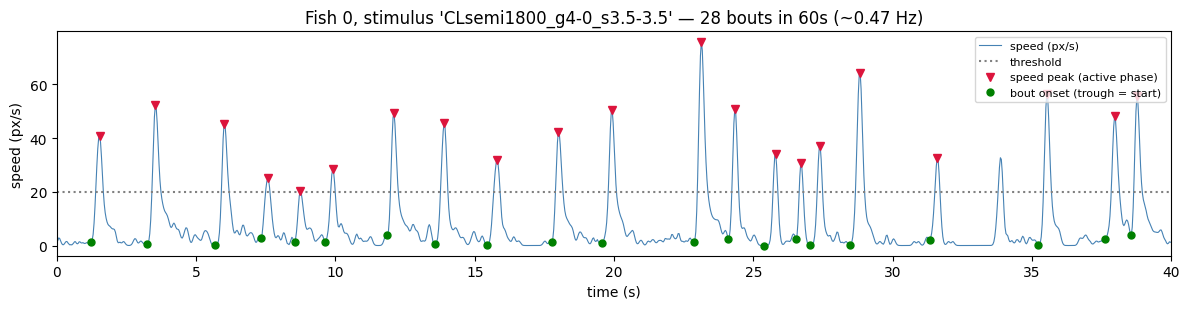

In [49]:
K = 1.0   # speed threshold factor (mean + K*std); tune for ~1-2 Hz

# take the first long CLsemi block of fish 0
blk = (df0["stimulus"] != df0["stimulus"].shift()).cumsum()
cand = df0.assign(_b=blk).groupby("_b").filter(
    lambda g: g["stimulus"].iloc[0].startswith("CLsemi") and len(g) > 600)
seg = cand[cand["_b"] == cand["_b"].iloc[0]].reset_index(drop=True)

# smoothed positions -> DETECTION only (locate the onset/peak frames). The raw
# positions (xr, yr) are what we plot and measure heading from further down.
x, y = fish_xy_px(seg, prefix0)
v = speed_px_s(x, y)
onsets, peaks = detect_bouts(x, y, K)   # onset = trough (bout start), peak = active phase
xr = seg[f"{prefix0}_x"].to_numpy(float)   # raw (unsmoothed) px
yr = seg[f"{prefix0}_y"].to_numpy(float)
t = np.arange(len(v)) / FPS

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, v, lw=0.8, color="steelblue", label="speed (px/s)")
ax.axhline(np.nanmean(v) + K * np.nanstd(v), color="gray", ls=":", label="threshold")
ax.plot(peaks / FPS, v[peaks], "v", color="crimson", ms=6, label="speed peak (active phase)")
ax.plot(onsets / FPS, v[onsets], "o", color="green", ms=5, label="bout onset (trough = start)")
ax.set_xlim(0, min(40, t[-1])); ax.set_xlabel("time (s)"); ax.set_ylabel("speed (px/s)")
ax.set_title(f"Fish 0, stimulus '{seg['stimulus'].iloc[0]}' — {len(onsets)} bouts in {len(seg)/FPS:.0f}s "
             f"(~{len(onsets)/(len(seg)/FPS):.2f} Hz)")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

## 6. The same block in 2D — trajectory coloured by bout

Each detected bout onset is a point along the path. This is the discretisation: a continuous track becomes a sequence of bouts.

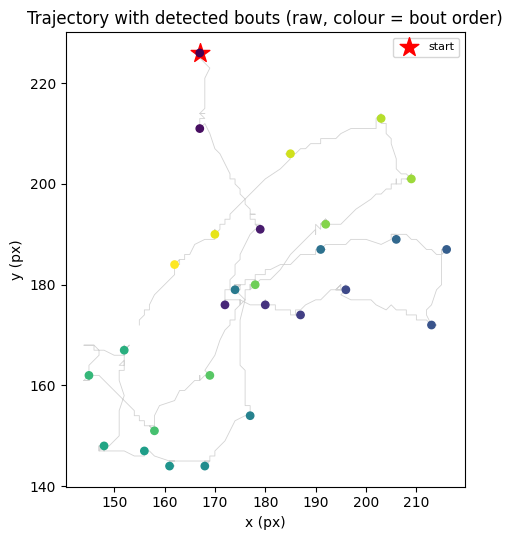

In [50]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(xr, yr, lw=0.6, color="lightgray", zorder=1)                          # raw path
ax.scatter(xr[onsets], yr[onsets], c=np.arange(len(onsets)), cmap="viridis", s=28, zorder=2)
ax.scatter([xr[onsets[0]]], [yr[onsets[0]]], marker="*", s=200, color="red", label="start")
ax.set_aspect("equal"); ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
ax.set_title("Trajectory with detected bouts (raw, colour = bout order)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 6b. Same trajectory — heading arrows over the **raw** path, coloured by speed

The same block, but each bout is an **arrow in its travel direction** over the **raw (unsmoothed) trajectory**, coloured by the **bout's speed**. Heading is taken **onset-to-onset** from the raw bout positions (`θᵢ = dir(onsetᵢ₊₁ − onsetᵢ)`), so each arrow points from this bout to the next — the direction the fish actually goes until the next bout. Smoothing was used only to *detect* the bouts (find the onset/peak frames), never to compute these positions or arrows. Sanity check: onset dots should land on real speed bursts, and arrows should run **along the raw path**; arrows that point sideways or against the path would flag a noisy heading.

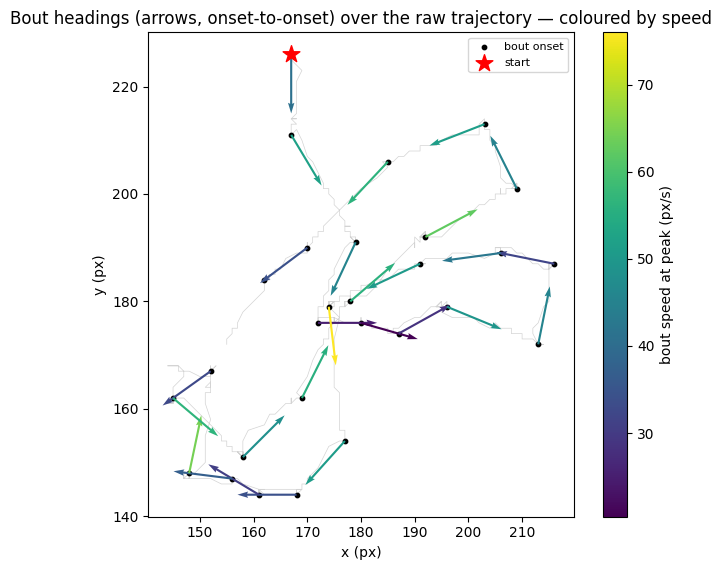

In [51]:
# Each bout drawn as a heading ARROW pointing to the NEXT bout, over the RAW
# (unsmoothed) trajectory. Heading is onset-to-onset from the raw discretized bout
# positions: theta_i = dir(onset_{i+1} - onset_i). Smoothing was used ONLY to
# detect the bouts, never to bend these arrows. Positions in pixels.
ox, oy = xr[onsets], yr[onsets]
theta = np.arctan2(np.diff(oy), np.diff(ox))        # onset-to-onset heading (raw)
bout_speed = v[peaks][:-1]                          # speed at the peak (px/s), aligned to theta
ax0, ay0 = ox[:len(theta)], oy[:len(theta)]         # arrow origin = bout onset

L = 11.0  # arrow length (px, ~3 mm at the nominal scale)
fig, ax = plt.subplots(figsize=(6.6, 5.8))
ax.plot(xr, yr, lw=0.5, color="lightgray", zorder=1)                 # raw path
ax.scatter(ox, oy, s=10, color="k", zorder=2, label="bout onset")    # detected onsets
q = ax.quiver(ax0, ay0, L * np.cos(theta), L * np.sin(theta), bout_speed,
              angles="xy", scale_units="xy", scale=1, cmap="viridis",
              width=0.005, zorder=3)
ax.scatter([ax0[0]], [ay0[0]], marker="*", s=160, color="red", zorder=4, label="start")
fig.colorbar(q, ax=ax, label="bout speed at peak (px/s)")
ax.set_aspect("equal"); ax.set_xlabel("x (px)"); ax.set_ylabel("y (px)")
ax.set_title("Bout headings (arrows, onset-to-onset) over the raw trajectory — coloured by speed")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()

## 7. Per-bout kinematics — heading, reorientation `dtheta`, `dt`, distance

Each bout has **two anchors**:
- **onset** (trough — speed minimum before the peak) → the bout *start*: used for **timing** (`dt`), **position** (`x_px, y_px`), **stimulus context** (`stim_angle`), and as the **heading/distance anchor**.
- **peak** (speed maximum) → the active phase, kept only for the **body-orientation cross-check** (`dtheta_ori`).

Heading is read **onset-to-onset** from the **raw** bout positions (in **pixels**), so each bout's heading is the net travel to the next bout (the direction the fish actually goes until then). Computing it from the discretized positions makes it robust to where in the bout the speed peaks and to 180° head/tail flips:
- **heading** $\theta_i = \mathrm{atan2}(\,y_{\text{onset}_{i+1}}-y_{\text{onset}_i},\; x_{\text{onset}_{i+1}}-x_{\text{onset}_i})$ — scale-free, so pixels vs mm make no difference
- **reorientation** $\delta\theta_i = \mathrm{wrap}(\theta_i - \theta_{i-1})$
- **dt** and **distance** (`distance_px`, plus a nominal-mm column) are the same onset-to-onset interval and leg.

Gaussian smoothing enters **only** into detecting the onset/peak frames; every measured quantity above uses the raw positions. We also keep `dtheta_ori` (body orientation at the peak, flip-corrected) as an independent cross-check.

In [52]:
def segment_fish(df, prefix, fish_id, speed_thresh_k, split_at_blocks=False,
                 onset_mode="trough"):
    """Segment one fish into bouts -> list of per-bout dict records.

    PIXEL-NATIVE: positions/distances are reported in pixels (no per-fish scaling).
    Two anchors per bout: onset (trough) = bout START (timing, position, stimulus,
    heading/distance anchor); peak = kept for the body-orientation cross-check.
    Smoothing is used ONLY to detect bout timing; heading/distance/position are
    measured from the RAW pixel positions. Split only at tracking gaps unless
    split_at_blocks=True.
    """
    df = df.reset_index(drop=True).copy()
    has_pos = df[f"{prefix}_x"].notna() & df[f"{prefix}_y"].notna()
    edges = (~has_pos) & has_pos.shift(fill_value=False)        # tracking gaps
    if split_at_blocks:
        edges = edges | df["stimulus"].ne(df["stimulus"].shift())
    df["_seg"] = edges.cumsum()

    records = []
    for sid, seg in df.groupby("_seg", sort=True):
        seg = seg[has_pos.loc[seg.index]].reset_index(drop=True)
        if len(seg) < 2 * DISP_WIN_FR + 2:
            continue
        x, y = fish_xy_px(seg, prefix)             # smoothed -> detection only
        onsets, peaks = detect_bouts(x, y, speed_thresh_k, onset_mode=onset_mode)
        if len(onsets) < 3:
            continue
        frames = seg["frame"].to_numpy()
        ori_raw = seg[f"{prefix}_ori"].to_numpy(dtype=float)
        xr = seg[f"{prefix}_x"].to_numpy(dtype=float)   # RAW px -> everything measured
        yr = seg[f"{prefix}_y"].to_numpy(dtype=float)

        # heading & distance from RAW onset positions -> net travel to the next
        # bout; dt from the same onsets (bout starts)
        ox, oy = xr[onsets], yr[onsets]
        theta = np.arctan2(np.diff(oy), np.diff(ox))   # onset-to-onset heading (raw)
        dist = np.hypot(np.diff(ox), np.diff(oy))       # px, onset-to-onset (raw)
        dt = np.diff(frames[onsets]) / FPS              # s, onset-to-onset

        # orientation cross-check: body orientation at the peak, flip-corrected
        ori_pk = ori_raw[peaks]
        mv = np.concatenate([theta, theta[-1:]])
        ori_c = np.where(np.cos(ori_pk - mv) < 0, wrap_pi(ori_pk + np.pi), ori_pk)

        for i in range(1, len(onsets) - 1):
            o = onsets[i]; row = seg.iloc[o]; f_ori = float(ori_raw[o])
            dtheta = wrap_pi(theta[i] - theta[i - 1])
            dtheta_ori = wrap_pi(ori_c[i] - ori_c[i - 1])
            stim = row["stimulus"]; ctx = parse_stimulus(stim)   # condition at onset
            rec = dict(
                fish_id=fish_id, segment_id=int(sid), bout_index=i,
                frame_onset=int(row["frame"]), t_onset_s=float(row["frame"]) / FPS,
                dtheta_rad=float(dtheta), dtheta_deg=float(np.degrees(dtheta)),
                dtheta_ori_deg=float(np.degrees(dtheta_ori)),
                dt_s=float(dt[i]), distance_px=float(dist[i]),
                distance_nominal_mm=float(dist[i] / PX_PER_MM),
                heading_rad=float(theta[i]), f_ori_rad=f_ori,
                x_px=float(xr[o]), y_px=float(yr[o]), stimulus=stim,
                stim_angle_rad=stim_angle_at(row, xr[o], yr[o], f_ori),
                **ctx,
            )
            adeg = abs(rec["dtheta_deg"])
            rec["bout_type"] = ("forward" if adeg < FORWARD_THRESH_DEG
                                else ("left" if dtheta > 0 else "right"))
            records.append(rec)
    return records


# demo on fish 0
rec0 = segment_fish(df0, prefix0, 0, K)
print(f"fish 0: {len(rec0)} bouts")
pd.DataFrame(rec0).head()

fish 0: 4272 bouts


,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dtheta_ori_deg,dt_s,distance_px,...,y_px,stimulus,stim_angle_rad,n_dots_left,n_dots_right,speed_left,speed_right,side,moving,bout_type
0,0,0,1,305,10.166667,0.680521,38.990994,31.913749,2.766667,19.104973,...,210.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,left
1,0,0,2,388,12.933333,-0.402222,-23.045598,-14.553128,0.933333,10.295630,...,229.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,right
2,0,0,3,416,13.866667,-0.033321,-1.909152,-2.750197,1.566667,11.661904,...,238.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward
3,0,0,4,463,15.433333,-0.047583,-2.726311,1.145916,11.866667,10.816654,...,248.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward
4,0,0,5,819,27.300000,-0.138640,-7.943472,-4.583662,1.200000,12.041595,...,257.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward


## 8. Run on all 15 fish and assemble the bout dataframe

In [53]:
all_records = []
for path in csvs:
    m = re.search(r"_f(\d+)_transformed_abs", path.name)
    fid = int(m.group(1)) if m else -1
    dfi = pd.read_csv(path)
    pref = next(re.match(r"(f\d+)_x$", c).group(1) for c in dfi.columns if re.match(r"(f\d+)_x$", c))
    recs = segment_fish(dfi, pref, fid, K)
    all_records.extend(recs)
    print(f"  fish {fid:>2}: {len(recs):>5} bouts")

bouts = pd.DataFrame(all_records)
print("\ntotal bouts:", len(bouts))
bouts.head()

  fish  0:  4272 bouts
  fish 10:  3129 bouts
  fish 11:  6143 bouts
  fish 12:  5674 bouts
  fish 13:  3824 bouts
  fish 14:  4725 bouts
  fish  1:  5273 bouts
  fish  2:  5526 bouts
  fish  3:  4816 bouts
  fish  4:  3258 bouts
  fish  5:  6686 bouts
  fish  6:  3137 bouts
  fish  7:  6378 bouts
  fish  8:  3199 bouts
  fish  9:  4550 bouts

total bouts: 70590


,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dtheta_ori_deg,dt_s,distance_px,...,y_px,stimulus,stim_angle_rad,n_dots_left,n_dots_right,speed_left,speed_right,side,moving,bout_type
0,0,0,1,305,10.166667,0.680521,38.990994,31.913749,2.766667,19.104973,...,210.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,left
1,0,0,2,388,12.933333,-0.402222,-23.045598,-14.553128,0.933333,10.295630,...,229.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,right
2,0,0,3,416,13.866667,-0.033321,-1.909152,-2.750197,1.566667,11.661904,...,238.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward
3,0,0,4,463,15.433333,-0.047583,-2.726311,1.145916,11.866667,10.816654,...,248.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward
4,0,0,5,819,27.300000,-0.138640,-7.943472,-4.583662,1.200000,12.041595,...,257.0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,none,False,forward


### Non-destructive border flag
Mirroring Le Goc's 5 mm ROI: flag (don't drop) bouts in the outer 5 mm shell, using an **empirical** dish centre (median position) and radius per fish — robust to the ROIdef/camera frame mismatch.

In [54]:
bouts["near_wall"] = False
for fid, g in bouts.groupby("fish_id"):
    cx, cy = g["x_px"].median(), g["y_px"].median()
    r = np.hypot(g["x_px"] - cx, g["y_px"] - cy)
    r_dish = np.quantile(r, 0.95)
    bouts.loc[g.index, "near_wall"] = (r > (r_dish - WALL_SHELL_PX)).to_numpy()
print("near_wall flagged:", int(bouts["near_wall"].sum()), "/", len(bouts))

near_wall flagged: 9234 / 70590


### Physical distance-to-border feature

A **pixel-native, scale-free** feature for boundary-aware models: for each bout onset,
the distance to the **physical** dish wall (from the raw ROIdef). `dist_to_border_px = R - r`
and `dist_to_border_norm = (R - r)/R` in [0,1] (1 at the centre, 0 at the wall), where
`r` is the distance from the physical dish centre and `R` the physical radius. Unlike
`near_wall` (empirical median centre + p95 radius), this is the *true* wall, so the two
diverge for off-centre fish (f0/f6/f14). No mm conversion -- the normalised column is exact.

In [55]:
# Physical distance-to-nearest-border feature (PIXEL-NATIVE, scale-free), from the
# RAW ROIdef (true 100 mm dish wall), mapped into this y-flipped frame:
#   centre=(x-xoff, diameter-(y-yoff)), radius unchanged; row i = fish i.
#   dist_to_border_px   = R - r         (~0 at the wall, ~R at the centre)
#   dist_to_border_norm = (R - r) / R   (1 centre -> 0 wall; exact, unit-free)
# Uses the PHYSICAL dish, unlike near_wall (each fish's own median centre + p95 radius);
# the two diverge for off-centre fish (f0/f6/f14). Mirrors scripts/segment_bouts.py.
roi_phys = pd.read_csv(ROOT / 'data' / 'data' / 'Original_data' / 'ROIdef2025-02-20T12_09_16.csv',
                       header=None, names=['xoff', 'yoff', 'diameter', 'x', 'y', 'radius'])
roi_phys['cx'] = roi_phys['x'] - roi_phys['xoff']
roi_phys['cy'] = roi_phys['diameter'] - (roi_phys['y'] - roi_phys['yoff'])
cx = bouts['fish_id'].map(roi_phys['cx']); cy = bouts['fish_id'].map(roi_phys['cy'])
R = bouts['fish_id'].map(roi_phys['radius'])
r = np.hypot(bouts['x_px'] - cx, bouts['y_px'] - cy)
bouts['dist_to_border_px'] = (R - r).astype(float)
bouts['dist_to_border_norm'] = ((R - r) / R).astype(float)
print('dist_to_border_norm: min %.3f  max %.3f  | %d bouts, no NaN=%s'
      % (bouts['dist_to_border_norm'].min(), bouts['dist_to_border_norm'].max(),
         len(bouts), bool(bouts[['dist_to_border_px', 'dist_to_border_norm']].isna().sum().sum() == 0)))

dist_to_border_norm: min 0.010  max 1.000  | 70590 bouts, no NaN=True


## 8b. Trajectory structure — how the continuous stream was cut

A **trajectory** (`segment_id`) is a maximal run of **continuously tracked** frames. The stream is cut **only at tracking gaps** — frames where the fish position is `NaN` (the tracker briefly lost the fish) — and **never** at stimulus-block or pause boundaries (that split is the off-by-default `--split-at-blocks`). So a bout can straddle a pause→stimulus transition, which is deliberate: it keeps the fish's first reaction to a newly-appeared stimulus.

Here tracking is essentially unbroken, so **each fish is a single ~3-hour trajectory** (15 fish → 15 trajectories). The stats below confirm this and give the per-trajectory lengths and bout counts.

fish                          : 15
trajectories (fish, segment)  : 15
segments per fish             : min 1, max 1  -> one per fish: tracking never broke
bouts per trajectory          : min 3129, median 4725, mean 4706, max 6686
duration per trajectory [min] : min 168.4, median 173.2, max 174.0  (~full ~174 min session)
trajectories with >=10 bouts (used by the HMMs): 15 / 15
total                         : 70590 bouts over 43.2 fish-hours
(rate_Hz is the average over the whole trajectory incl. idle stretches; the ~0.81 Hz in Sect. 9 is 1/median(dt), the typical instantaneous rate.)


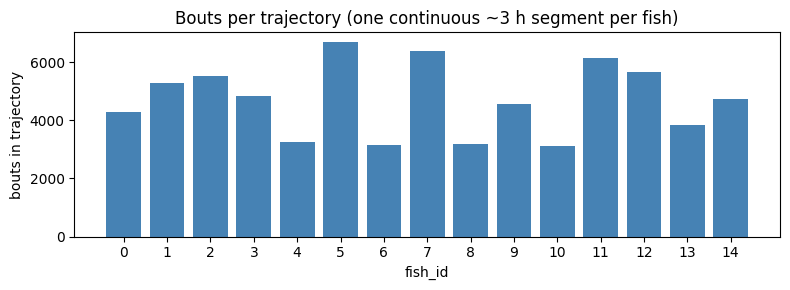

,fish_id,segment_id,n_bouts,dur_min,rate_Hz
0,0,0,4272,174.0,0.41
1,1,0,5273,173.2,0.51
2,2,0,5526,174.0,0.53
3,3,0,4816,173.2,0.46
4,4,0,3258,173.1,0.31
5,5,0,6686,173.0,0.64
6,6,0,3137,171.9,0.30
7,7,0,6378,173.6,0.61
8,8,0,3199,173.1,0.31
9,9,0,4550,173.9,0.44


In [56]:
# Trajectory = a continuous tracked segment. The stream is split ONLY at tracking
# gaps (NaN fish positions), never at stimulus/pause boundaries. Below: how many
# trajectories resulted, how long they are, and how many bouts each holds.
traj = bouts.groupby(["fish_id", "segment_id"])
per = traj.agg(
    n_bouts=("bout_index", "size"),
    dur_min=("t_onset_s", lambda s: (s.max() - s.min()) / 60),   # first-to-last bout
).reset_index()
per["rate_Hz"] = per["n_bouts"] / (per["dur_min"] * 60)          # avg over the trajectory
seg_per_fish = bouts.groupby("fish_id")["segment_id"].nunique()

print(f"fish                          : {bouts['fish_id'].nunique()}")
print(f"trajectories (fish, segment)  : {len(per)}")
print(f"segments per fish             : min {seg_per_fish.min()}, max {seg_per_fish.max()}"
      + ("  -> one per fish: tracking never broke" if seg_per_fish.max() == 1
         else "  -> gaps split some fish"))
print(f"bouts per trajectory          : min {per.n_bouts.min()}, median {per.n_bouts.median():.0f}, "
      f"mean {per.n_bouts.mean():.0f}, max {per.n_bouts.max()}")
print(f"duration per trajectory [min] : min {per.dur_min.min():.1f}, median {per.dur_min.median():.1f}, "
      f"max {per.dur_min.max():.1f}  (~full ~174 min session)")
print(f"trajectories with >=10 bouts (used by the HMMs): {(per.n_bouts >= 10).sum()} / {len(per)}")
print(f"total                         : {len(bouts)} bouts over {per.dur_min.sum()/60:.1f} fish-hours")
print("(rate_Hz is the average over the whole trajectory incl. idle stretches; the "
      "~0.81 Hz in Sect. 9 is 1/median(dt), the typical instantaneous rate.)")

fig, ax = plt.subplots(figsize=(8, 3.0))
o = per.sort_values("fish_id")
ax.bar(o["fish_id"].astype(str), o["n_bouts"], color="steelblue")
ax.set_xlabel("fish_id"); ax.set_ylabel("bouts in trajectory")
ax.set_title("Bouts per trajectory (one continuous ~3 h segment per fish)")
plt.tight_layout(); plt.show()

display(per.assign(dur_min=per["dur_min"].round(1), rate_Hz=per["rate_Hz"].round(2)))

## 9. Diagnostics — does it look like real zebrafish swimming?

Sanity targets from Le Goc: **bout rate ~1–2 Hz**; reorientation histogram peaked at 0 (forward) with turn shoulders.

In [57]:
rate = 1.0 / bouts["dt_s"].median()
print(f"fish                  : {bouts['fish_id'].nunique()}")
print(f"median interbout dt   : {bouts['dt_s'].median():.3f} s  (~{rate:.2f} Hz)")
print(f"median distance       : {bouts['distance_px'].median():.2f} px "
      f"({bouts['distance_nominal_mm'].median():.2f} nominal mm)")
print(f"|dtheta| median       : {bouts['dtheta_deg'].abs().median():.1f} deg")
print(f"forward frac (disp)   : {(bouts['dtheta_deg'].abs() < FORWARD_THRESH_DEG).mean():.2f}")
print(f"forward frac (ori)    : {(bouts['dtheta_ori_deg'].abs() < FORWARD_THRESH_DEG).mean():.2f}")
print(f"bouts during stimulus : {(bouts['side'] != 'none').sum()}")
print("\nbout-type fractions:", bouts["bout_type"].value_counts(normalize=True).round(3).to_dict())

fish                  : 15
median interbout dt   : 1.233 s  (~0.81 Hz)
median distance       : 15.03 px (4.10 nominal mm)
|dtheta| median       : 39.0 deg
forward frac (disp)   : 0.11
forward frac (ori)    : 0.13
bouts during stimulus : 40048

bout-type fractions: {'right': 0.449, 'left': 0.44, 'forward': 0.111}


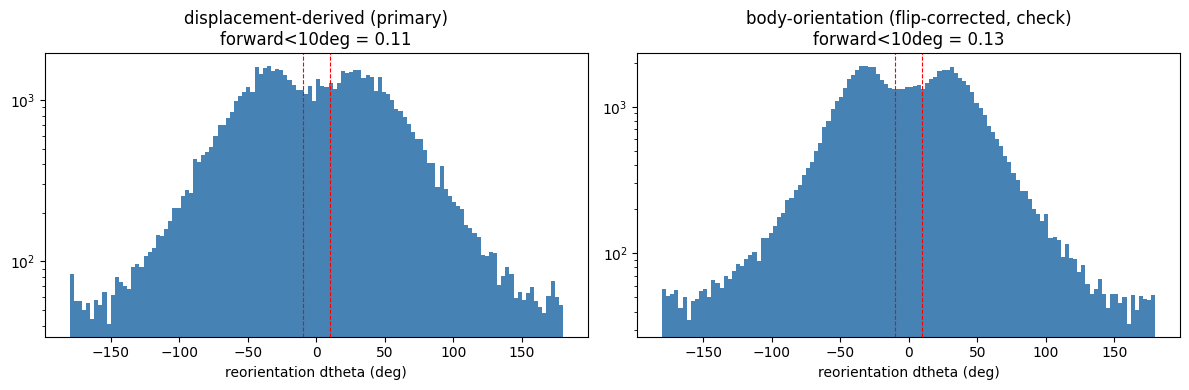

In [58]:
# reorientation histograms: displacement-derived vs orientation cross-check
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, title in [(ax[0], "dtheta_deg", "displacement-derived (primary)"),
                      (ax[1], "dtheta_ori_deg", "body-orientation (flip-corrected, check)")]:
    a.hist(bouts[col].clip(-180, 180), bins=120, color="steelblue")
    a.axvline(10, color="r", ls="--", lw=0.8); a.axvline(-10, color="r", ls="--", lw=0.8)
    a.set_yscale("log"); a.set_xlabel("reorientation dtheta (deg)")
    a.set_title(f"{title}\nforward<10deg = {(bouts[col].abs() < 10).mean():.2f}")
plt.tight_layout(); plt.show()

**Read this carefully.** The displacement-derived `dtheta` (left) is **peaked at 0** (forward-biased) but **broad** — *not* the crisp trimodal shape of the open-field Le Goc/HMM data. The orientation-based check (right) is **bimodal with a dip at 0**, the signature of 180° head/tail flips — which is why displacement-derived heading is the better choice here.

The breadth is a **data-quality limit**, not a pipeline bug: integer-pixel positions (~0.4 mm) over ~2–4 mm bouts, unreliable body orientation, and a small stimulus-driven dish. An HMM (designed for overlapping distributions) may still recover clean F/L/R states.

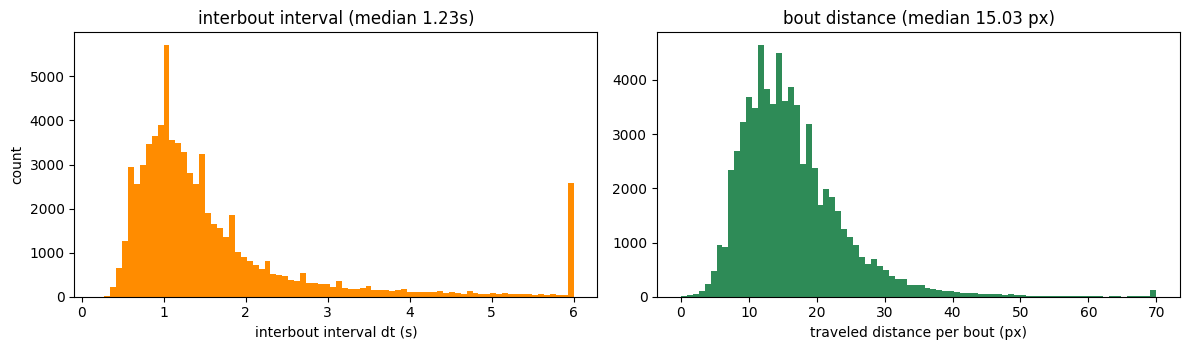

In [59]:
# interbout interval and distance distributions
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(bouts["dt_s"].clip(0, 6), bins=80, color="darkorange")
ax[0].set_xlabel("interbout interval dt (s)"); ax[0].set_ylabel("count")
ax[0].set_title(f"interbout interval (median {bouts['dt_s'].median():.2f}s)")
ax[1].hist(bouts["distance_px"].clip(0, 70), bins=80, color="seagreen")
ax[1].set_xlabel("traveled distance per bout (px)")
ax[1].set_title(f"bout distance (median {bouts['distance_px'].median():.2f} px)")
plt.tight_layout(); plt.show()

## 10. Stimulus context — does the side of the dots bias turning?

Each bout carries the active stimulus. Here we compare the mean **signed reorientation** (positive = leftward turn) for bouts during left-only vs right-only dot stimuli. This is the kind of question this segmented dataset enables.

,count,mean,median
side,,,
left,17773,1.14,0.84
right,17005,-1.31,-2.13


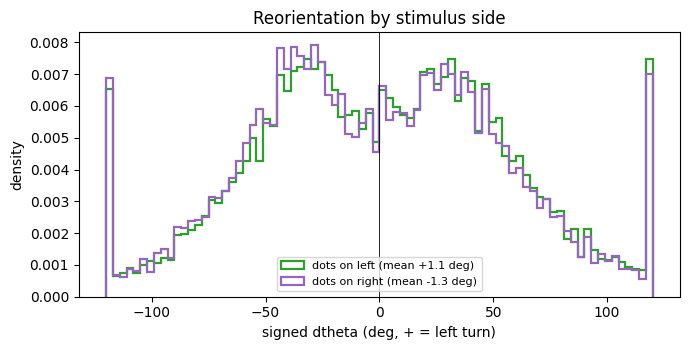

In [60]:
stim_bouts = bouts[(bouts["side"].isin(["left", "right"])) & (~bouts["near_wall"])]
summary = stim_bouts.groupby("side")["dtheta_deg"].agg(["count", "mean", "median"]).round(2)
display(summary)

fig, ax = plt.subplots(figsize=(7, 3.6))
for side, c in [("left", "tab:green"), ("right", "tab:purple")]:
    d = stim_bouts.loc[stim_bouts["side"] == side, "dtheta_deg"]
    ax.hist(d.clip(-120, 120), bins=80, histtype="step", lw=1.6, density=True, color=c,
            label=f"dots on {side} (mean {d.mean():+.1f} deg)")
ax.axvline(0, color="k", lw=0.6); ax.set_xlabel("signed dtheta (deg, + = left turn)")
ax.set_ylabel("density"); ax.set_title("Reorientation by stimulus side")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 11. Save the bout dataset

In [61]:
OUT_CSV.parent.mkdir(parents=True, exist_ok=True)
bouts.to_csv(OUT_CSV, index=False)
print(f"saved {len(bouts)} bouts -> {OUT_CSV}")
print("columns:", list(bouts.columns))

saved 70590 bouts -> c:\Users\arthu\mp_semiCL_behavior\data\bouts_GsizeMotionSingle.csv
columns: ['fish_id', 'segment_id', 'bout_index', 'frame_onset', 't_onset_s', 'dtheta_rad', 'dtheta_deg', 'dtheta_ori_deg', 'dt_s', 'distance_px', 'distance_nominal_mm', 'heading_rad', 'f_ori_rad', 'x_px', 'y_px', 'stimulus', 'stim_angle_rad', 'n_dots_left', 'n_dots_right', 'speed_left', 'speed_right', 'side', 'moving', 'bout_type', 'near_wall', 'dist_to_border_px', 'dist_to_border_norm']


In [62]:
bouts

,fish_id,segment_id,bout_index,frame_onset,t_onset_s,dtheta_rad,dtheta_deg,dtheta_ori_deg,dt_s,distance_px,...,n_dots_left,n_dots_right,speed_left,speed_right,side,moving,bout_type,near_wall,dist_to_border_px,dist_to_border_norm
0,0,0,1,305,10.166667,0.680521,38.990994,31.913749,2.766667,19.104973,...,NaN,NaN,NaN,NaN,none,False,left,True,133.637558,0.707077
1,0,0,2,388,12.933333,-0.402222,-23.045598,-14.553128,0.933333,10.295630,...,NaN,NaN,NaN,NaN,none,False,right,False,126.198726,0.667718
2,0,0,3,416,13.866667,-0.033321,-1.909152,-2.750197,1.566667,11.661904,...,NaN,NaN,NaN,NaN,none,False,forward,False,123.930806,0.655719
3,0,0,4,463,15.433333,-0.047583,-2.726311,1.145916,11.866667,10.816654,...,NaN,NaN,NaN,NaN,none,False,forward,False,119.934813,0.634576
4,0,0,5,819,27.300000,-0.138640,-7.943472,-4.583662,1.200000,12.041595,...,NaN,NaN,NaN,NaN,none,False,forward,False,115.209757,0.609575
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70585,9,0,4546,313106,10436.866667,-1.211284,-69.401445,-69.911468,2.600000,34.132096,...,0.0,1.0,3.5,3.5,right,True,right,False,129.902278,0.738081
70586,9,0,4547,313184,10439.466667,-1.302935,-74.652702,-67.322541,1.366667,22.360680,...,0.0,1.0,3.5,3.5,right,True,right,False,164.000000,0.931818
70587,9,0,4548,313225,10440.833333,2.176341,124.695154,101.767922,0.866667,19.798990,...,0.0,1.0,3.5,3.5,right,True,left,False,152.590600,0.866992
70588,9,0,4549,313251,10441.700000,-0.628796,-36.027373,-15.985522,3.166667,38.470768,...,0.0,1.0,3.5,3.5,right,True,right,False,166.000000,0.943182


---
### Notes & next steps
- **Tuning**: lower `K` (cell 5) → more bouts / higher rate; aim for ~1–1.5 Hz. The CLI script takes `--speed-thresh-k`.
- **Cleaner `dtheta`**: would require the original sub-pixel `PositionTxt` (not shipped in `data.zip`) re-run through the transform without integer rounding.
- **HMM-ready export**: emit per-trajectory `dtheta` sequences to HDF5 mirroring `behavior_free_swimming.h5` to feed the ZebrafishHMM pipeline.
- The batch script equivalent of this notebook is `scripts/segment_bouts.py`.